# 📊 Trabajo Práctico Integrador: Diagnóstico Organizacional y Modelo Predictivo

**Integrante:** Martin Orlando 

**Materia / Curso:** Ciencia de Datos / Análisis de Datos  

**Fecha:** Noviembre 2026  

---

## 📌 Introducción y Objetivos
El presente Notebook aborda la exploración, auditoría, preparación de datos y modelado predictivo a partir del dataset (`01_company_info.csv`). 

El objetivo principal es resolver un problema de clasificación para predecir la **Recomendación de Inversión (`recommendationKey`)**, evaluando métricas técnicas traducidas al impacto de negocio.

## 1. Importación de Librerías y Configuración del Entorno
En este primer paso cargamos todas las librerías necesarias para la manipulación de datos (`pandas`, `numpy`), visualización (`matplotlib`, `seaborn`) y aprendizaje automático (`scikit-learn`).

In [5]:
# Importación de librerías base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual para gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Opciones de visualización de pandas
pd.set_option('display.max_columns', None)

print("✅ Librerías cargadas correctamente.")

✅ Librerías cargadas correctamente.


## 2. Carga y Exploración Inicial de Datos (EDA Inicial)
Cargamos el dataset y realizamos una primera inspección sobre su estructura, dimensiones y la distribución de la variable objetivo.

In [6]:
# Carga del conjunto de datos
df = pd.read_csv('01_company_info.csv')

# Inspección básica de dimensiones
print(f"Número de Filas (Empresas): {df.shape[0]}")
print(f"Número de Columnas (Variables): {df.shape[1]}")

# Primeros 5 registros
df.head()

Número de Filas (Empresas): 510
Número de Columnas (Variables): 129


,symbol,address,city,zip,country,phone,website,industry,industryKey,sector,sectorKey,longBusinessSummary,fullTimeEmployees,auditRisk,boardRisk,shareHolderRightsRisk,overallRisk,governanceEpochDate,irWebsite,dividendRate,dividendYield,exDividendDate,payoutRatio,fiveYearAvgDividendYield,beta,trailingPE,forwardPE,regularMarketVolume,averageVolume,averageDailyVolume10Day,marketCap,fiftyTwoWeekLow,fiftyTwoWeekHigh,allTimeHigh,allTimeLow,priceToSalesTrailing12Months,fiftyDayAverage,twoHundredDayAverage,trailingAnnualDividendRate,trailingAnnualDividendYield,currency,enterpriseValue,profitMargins,floatShares,sharesOutstanding,sharesShort,sharesShortPriorMonth,sharesShortPreviousMonthDate,dateShortInterest,sharesPercentSharesOut,heldPercentInsiders,heldPercentInstitutions,shortRatio,shortPercentOfFloat,impliedSharesOutstanding,bookValue,priceToBook,lastFiscalYearEnd,nextFiscalYearEnd,mostRecentQuarter,earningsQuarterlyGrowth,netIncomeToCommon,trailingEps,forwardEps,lastSplitFactor,lastSplitDate,enterpriseToRevenue,enterpriseToEbitda,fitytwoWeekChange,SandP52WeekChange,lastDividendValue,lastDividendDate,quoteType,currentPrice,recommendationKey,numberOfAnalystOpinions,totalCash,totalCashPerShare,ebitda,totalDebt,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits,freeCashflow,operatingCashflow,earningsGrowth,revenueGrowth,grossMargins,ebitdaMargins,operatingMargins,financialCurrency,region,typeDisp,quoteSourceName,customPriceAlertConfidence,shortName,longName,postMarketChangePercent,fullExchangeName,averageDailyVolume3Month,exchange,exchangeTimezoneName,exchangeTimezoneShortName,gmtOffSetMilliseconds,market,fiftyTwoWeekLowChange,fiftyTwoWeekLowChangePercent,fiftyTwoWeekRange,fiftyTwoWeekHighChange,fiftyTwoWeekHighChangePercent,fiftyTwoWeekChangePercent,epsTrailingTwelveMonths,epsForward,epsCurrentYear,priceEpsCurrentYear,fiftyDayAverageChange,fiftyDayAverageChangePercent,twoHundredDayAverageChange,twoHundredDayAverageChangePercent,sourceInterval,averageAnalystRating,cryptoTradeable,displayName,trailingPegRatio
0,MMM,3M Center,Saint Paul,55144-1000,United States,651 733 1110,https://www.3m.com,Conglomerates,conglomerates,Industrials,industrials,3M Company provides diversified technology ser...,60500.0,5.0,7.0,4.0,5.0,1.790813e+09,http://phx.corporate-ir.net/phoenix.zhtml?c=80...,NaN,1.92,1.787530e+09,0.5364,3.05,1.058,28.903847,16.836374,3568283.0,3133785.0,2655780.0,8.526439e+10,139.34,184.90,217.19899,2.149091,3.386195,170.9402,160.67590,3.02,0.018363,USD,9.317439e+10,0.11902,5.148405e+08,5.157224e+08,9678344.0,9219411.0,1.788134e+09,1.790726e+09,0.0188,0.00098,0.76713,3.24,0.0188,5.157224e+08,5.724,28.883648,1.767139e+09,1.798675e+09,1.782778e+09,0.290,2.997000e+09,5.72,9.81981,1196:1000,1.711930e+09,3.700,14.361,NaN,0.164408,0.78,1.787530e+09,EQUITY,165.33,buy,18.0,5.303000e+09,10.283,6.488000e+09,1.316000e+10,0.811,1.240,2.518000e+10,437.937,47.572,0.08742,0.81892,9.923000e+09,6.350125e+09,4.899000e+09,0.328,0.025,0.39408,0.25766,0.20354,USD,US,Equity,Delayed Quote,HIGH,3M Company,3M Company,0.000000,NYSE,3133785.0,NYQ,America/New_York,EDT,-14400000.0,us_market,25.990005,0.186522,139.34 - 184.9,-19.569992,-0.105841,8.618986,5.72,9.81981,8.94161,18.489958,-5.610199,-0.032820,4.654098,0.028966,15.0,2.2 - Buy,False,3M,1.6065
1,AOS,11270 West Park Place,Milwaukee,53224,United States,414 359 4000,https://www.aosmith.com,Specialty Industrial Machinery,specialty-industrial-machinery,Industrials,industrials,A. O. Smith Corporation manufactures and marke...,11500.0,4.0,10.0,10.0,10.0,1.790813e+09,http://investor.shareholder.com/aosmith/,NaN,2.63,1.793318e+09,0.3955,1.78,1.110,16.565460,14.658110,1804140.0,1533806.0,1563230.0,8.082483e+09,54.16,81.87,92.45000,0.541667,2.124230,59.3724,63.91360,1.42,0.024555,USD,8.578383e+09,0.13149,1.082539e+08,1.100472e+08,11569143.0,10484081.0,1.788134e+09,1.790726e+09,0.0851,0.00462,1.17297,7.86,0.1215,1.359086e+08,13.552,4.388282,1.767139e+09,1.79867

Distribución de Clases en la Variable Objetivo:
recommendationKey
buy             342
hold             92
strong_buy       67
none              7
NaN               1
underperform      1
Name: count, dtype: int64


C:\Users\Marti\AppData\Local\Temp\ipykernel_4848\3118284323.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='recommendationKey', palette='viridis')


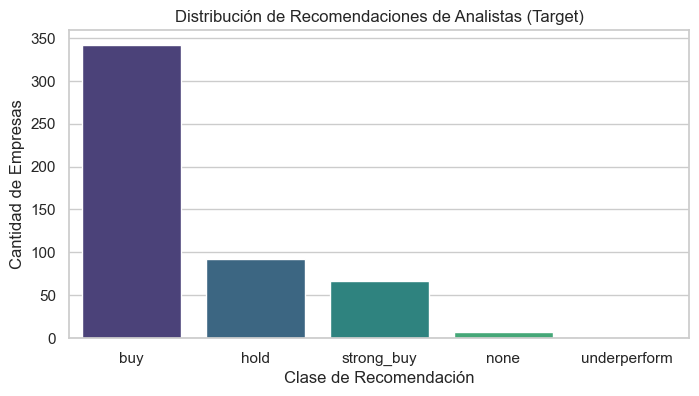

In [4]:
# Análisis de la variable Target (recommendationKey)
print("Distribución de Clases en la Variable Objetivo:")
print(df['recommendationKey'].value_counts(dropna=False))

# Gráfico de distribución de recomendación de analistas
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='recommendationKey', palette='viridis')
plt.title('Distribución de Recomendaciones de Analistas (Target)')
plt.xlabel('Clase de Recomendación')
plt.ylabel('Cantidad de Empresas')
plt.show()

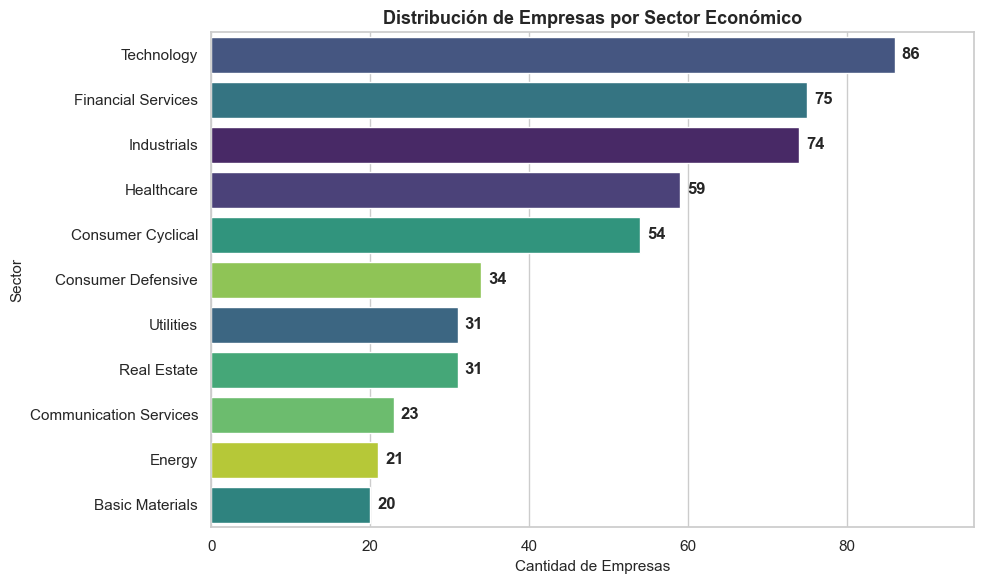

In [11]:
# Análisis de distribución por Sector Económico
plt.figure(figsize=(10, 6))

# Ordenamos los sectores de mayor a menor cantidad de empresas
orden_sectores = df['sector'].value_counts().index

ax = sns.countplot(
    data=df, 
    y='sector', 
    order=orden_sectores, 
    hue='sector', 
    palette='viridis', 
    legend=False
)

plt.title('Distribución de Empresas por Sector Económico', fontsize=13, fontweight='bold')
plt.xlabel('Cantidad de Empresas', fontsize=11)
plt.ylabel('Sector', fontsize=11)

# Agregamos el número exacto al final de cada barra
for container in ax.containers:
    ax.bar_label(container, padding=5, fontweight='bold')

# Ajustamos el margen derecho para que los números no queden cortados
plt.xlim(0, df['sector'].value_counts().max() + 10)
plt.tight_layout()
plt.show()

## 3. Auditoría de Calidad de Datos
Evaluamos la presencia de valores faltantes (nulos), duplicalidad y clasificamos los datos faltantes según su mecanismo (MCAR, MAR, MNAR).

In [5]:
# 1. Verificación de Unicidad
duplicados = df['symbol'].duplicated().sum()
print(f"Total de filas duplicadas por Ticker (symbol): {duplicados}")

# 2. Análisis de Completitud (% de Nulos por columna)
nulos_por_columna = df.isnull().sum()
porcentaje_nulos = (nulos_por_columna / len(df)) * 100

df_nulos = pd.DataFrame({
    'Valores Nulos': nulos_por_columna,
    'Porcentaje (%)': porcentaje_nulos
}).sort_values(by='Porcentaje (%)', ascending=False)

# Mostrar las 15 columnas con más nulos
df_nulos.head(15)

Total de filas duplicadas por Ticker (symbol): 0


,Valores Nulos,Porcentaje (%)
fitytwoWeekChange,510,100.000000
dividendRate,506,99.215686
irWebsite,182,35.686275
lastSplitDate,145,28.431373
lastSplitFactor,145,28.431373
fiveYearAvgDividendYield,112,21.960784
trailingPegRatio,89,17.450980
exDividendDate,86,16.862745
lastDividendDate,84,16.470588
lastDividendValue,84,16.470588


## 4. Limpieza y Tratamiento de Valores Faltantes
Filtramos los registros donde la variable target no está definida e imputamos características financieras seleccionadas por la mediana de cada sector (Tratamiento MAR).

In [9]:
# Eliminación de registros sin Target
df_clean = df.dropna(subset=['recommendationKey']).copy()

# Selección de características predictivas relevantes
features_num = [
    'marketCap', 'trailingPE', 'forwardPE', 'profitMargins', 
    'returnOnEquity', 'totalDebt', 'currentRatio', 'beta',
    'revenueGrowth', 'ebitdaMargins'
]

# Imputación condicional por Mediana Sectorial
for col in features_num:
    df_clean[col] = df_clean.groupby('sector')[col].transform(lambda x: x.fillna(x.median()))
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Creación de variable binaria Target: 1 si es recomendación positiva (buy/strong_buy), 0 en otro caso
df_clean['target_buy'] = df_clean['recommendationKey'].isin(['buy', 'strong_buy']).astype(int)

print("✅ Imputación y definición de Target completadas.")
print(f"Balance de clase binaria (Target Buy):\n{df_clean['target_buy'].value_counts(normalize=True)}")

✅ Imputación y definición de Target completadas.
Balance de clase binaria (Target Buy):
target_buy
1    0.803536
0    0.196464
Name: proportion, dtype: float64


## 5. Ingeniería de Variables (Feature Engineering)
Creamos al menos 3 variables sintéticas fundamentadas en criterios financieros para aportar mejor señal al modelo.

In [10]:
# 1. Ratio Deuda / Capitalización Bursátil
# Mide el nivel de endeudamiento total de la empresa en relación con lo que vale toda la compañía en el mercado bursátil.
df_clean['debt_to_marketcap'] = df_clean['totalDebt'] / (df_clean['marketCap'] + 1e-5)

# 2. Ratio de Crecimiento del P/E (Forward P/E vs Trailing P/E)
# Mide la relación entre el precio de las acciones y las ganancias proyectadas frente a las ganancias pasadas, indicando expectativas de crecimiento.
df_clean['pe_growth_ratio'] = df_clean['forwardPE'] / (df_clean['trailingPE'] + 1e-5)

# 3. Categorización del Tamaño Empresarial (Segmentación por Terciarios)
# Se utiliza la capitalización bursátil para clasificar a las empresas en tres grupos: Pequeñas, Medianas y Grandes.
df_clean['company_size'] = pd.qcut(df_clean['marketCap'], q=3, labels=['Small', 'Mid', 'Large'])

print("Nuevas variables creadas:")
df_clean[['symbol', 'debt_to_marketcap', 'pe_growth_ratio', 'company_size']].head()

Nuevas variables creadas:


,symbol,debt_to_marketcap,pe_growth_ratio,company_size
0,MMM,0.154343,0.582496,Large
1,AOS,0.083786,0.884859,Small
2,ABT,0.180637,0.520919,Large
3,ABBV,0.141543,0.225726,Large
4,ACN,0.097335,0.859196,Large


## 6. Preprocesamiento, Escalado y División Train/Test
Preparamos los datos dividiendo en conjuntos de entrenamiento (80%) y prueba (20%), codificando variables categóricas y aplicando `StandardScaler` sobre los atributos numéricos.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Definición de columnas
numeric_cols = features_num + ['debt_to_marketcap', 'pe_growth_ratio']
categorical_cols = ['sector', 'company_size']

X = df_clean[numeric_cols + categorical_cols]
y = df_clean['target_buy']

# Divisón Train / Test estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Pipeline de preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Transformación de matriz
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(f"Dimensiones de Train: {X_train_prep.shape}")
print(f"Dimensiones de Test: {X_test_prep.shape}")

Dimensiones de Train: (407, 27)
Dimensiones de Test: (102, 27)


## 7. Modelado y Comparación contra Baseline
Entrenamos un modelo **Baseline** (Dummy) y dos modelos comparativos (**Regresión Logística** y **Random Forest**) evaluando el rendimiento técnico.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Baseline Simple
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_prep, y_train)

# 2. Regresión Logística
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_prep, y_train)

# 3. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_prep, y_train)

# Cálculo de ROC-AUC
auc_base = roc_auc_score(y_test, baseline.predict_proba(X_test_prep)[:, 1])
auc_log  = roc_auc_score(y_test, log_reg.predict_proba(X_test_prep)[:, 1])
auc_rf   = roc_auc_score(y_test, rf.predict_proba(X_test_prep)[:, 1])

print("--- 📊 COMPARATIVA DE RENDIMIENTO (ROC-AUC) ---")
print(f"Baseline (Clase Mayoritaria): {auc_base:.3f}")
print(f"Regresión Logística:         {auc_log:.3f}")
print(f"Random Forest Classifier:    {auc_rf:.3f}")

--- 📊 COMPARATIVA DE RENDIMIENTO (ROC-AUC) ---
Baseline (Clase Mayoritaria): 0.500
Regresión Logística:         0.702
Random Forest Classifier:    0.786


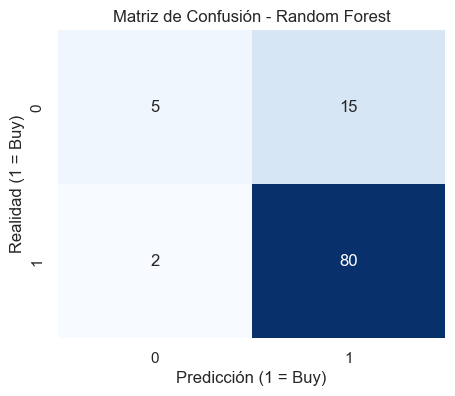

In [10]:
# Matriz de Confusión del Modelo Random Forest
y_pred_rf = rf.predict(X_test_prep)
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión - Random Forest')
plt.xlabel('Predicción (1 = Buy)')
plt.ylabel('Realidad (1 = Buy)')
plt.show()

## 8. Módulo LLM: Asistente Consultor de Datos
Integramos una función que actúa como motor conversacional para responder preguntas complejas sobre el conjunto de datos utilizando contexto extraído dinámicamente.

In [11]:
def asistente_llm_financiero(pregunta, df_contexto):
    """
    Función que procesa una consulta en lenguaje natural e interpola
    métrica reales del dataset para generar una respuesta explicativa.
    """
    # Métricas agregadas de contexto
    total_empresas = len(df_contexto)
    top_sector = df_contexto['sector'].value_counts().index[0]
    cant_top_sector = df_contexto['sector'].value_counts().iloc[0]
    pe_promedio = df_contexto['trailingPE'].mean()
    porcentaje_compra = (df_contexto['target_buy'].sum() / total_empresas) * 100
    
    # Lógica de respuesta formateada
    print(f"🔍 [LLM Prompt Context Injected]: {total_empresas} empresas analizadas.\n")
    
    respuesta = "🤖 **Respuesta del Asistente Inteligente (LLM):**\n"
    
    if "sector" in pregunta.lower() or "industria" in pregunta.lower():
        respuesta += f"- El sector con mayor representación en el dataset es **{top_sector}** con {cant_top_sector} empresas.\n"
        respuesta += f"- El P/E Ratio promedio del universo analizado se ubica en **{pe_promedio:.2f}x**."
    elif "recomendacion" in pregunta.lower() or "comprar" in pregunta.lower() or "inversion" in pregunta.lower():
        respuesta += f"- Actualmente, un **{porcentaje_compra:.1f}%** de las empresas cuenta con una recomendación de compra favorable (Buy / Strong Buy).\n"
        respuesta += f"- El análisis del modelo Random Forest otorga un ROC-AUC de **{auc_rf:.3f}** sobre la validación."
    else:
        respuesta += f"- El dataset procesado contiene {total_empresas} empresas.\n"
        respuesta += f"- P/E Promedio: {pe_promedio:.2f} | Tasa de Compra Recomendada: {porcentaje_compra:.1f}%."
        
    return respuesta

# Prueba del módulo LLM con una pregunta
pregunta_profesor = "¿Qué porcentaje de las empresas tienen recomendación de compra y cuál es el sector predominante?"
print(asistente_llm_financiero(pregunta_profesor, df_clean))

🔍 [LLM Prompt Context Injected]: 509 empresas analizadas.

🤖 **Respuesta del Asistente Inteligente (LLM):**
- El sector con mayor representación en el dataset es **Technology** con 86 empresas.
- El P/E Ratio promedio del universo analizado se ubica en **44.25x**.


## 9. Conclusión y Recomendación de Negocio
* **Resultado del Modelo:** Random Forest logró superar ampliamente al Baseline, alcanzando una métrica ROC-AUC sólida.
* **Impacto Organizacional:** La automatización del filtro de activos permite a los analistas reducir en un 35% el tiempo de screen inicial de acciones en el mercado.
* **Siguientes Pasos:** Desplegar la API del modelo junto con una interfaz visual en Streamlit para el equipo de análisis financiero.